In [2]:
!pip install torch torchvision

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 554.6/554.6 MB 27.1 MB/s  0:00:10m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 553.1/553.1 MB 28.1 MB/s  0:00:10m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.1/170.1 MB 58.7 MB/s  0:00:02m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.0/216.0 MB 66.7 MB/s  0:00:03m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.4/60.4 MB 68.7 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.0/7.0 MB 61.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.1/423.1 MB 31.3 MB/s  0:00:08m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.7/10.7 MB 53.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.2/90.2 MB 61.3 MB/s  0:00:016m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 56.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 214.1/214.1 MB 47.4 MB/s  0:00:04m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 

In [4]:
!pip install matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 58.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 46.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 56.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [matplotlib]6 [matplotlib]

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python3 -m pip install --upgrade pip


In [14]:
!pip install matplotlib


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python3 -m pip install --upgrade pip


In [16]:
!pip install scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 50.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 50.4 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [scikit-learn] [scikit-learn]

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python3 -m pip install --upgrade pip


In [5]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torchvision
from torchvision import transforms
import matplotlib.pyplot as plt

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, "| urządzenie:", device)

PyTorch: 2.14.1+cu130 | urządzenie: cpu


In [6]:
mean, std = 0.2860, 0.3530
tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((mean,), (std,)),
])

train_ds = torchvision.datasets.FashionMNIST("./data", train=True, download=True, transform=tf)
test_ds = torchvision.datasets.FashionMNIST("./data", train=False, download=True, transform=tf)
classes = train_ds.classes
print("Klasy:", classes)
print("Trening:", len(train_ds), "| Test:", len(test_ds))

train_dl = DataLoader(train_ds, batch_size=128, shuffle=True)
test_dl = DataLoader(test_ds, batch_size=256, shuffle=False)

100.0%
100.0%
100.0%
100.0%


Klasy: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
Trening: 60000 | Test: 10000


In [7]:
class MLP1(nn.Module):
    def __init__(self, in_dim=28*28, hidden=(128,), n_classes=10):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_dim, hidden[0]), nn.ReLU(),
            nn.Linear(hidden[0], n_classes),
        )
    def forward(self, x):
        return self.net(x)

class MLP2(nn.Module):
    def __init__(self, in_dim=28*28, hidden=(256, 128), n_classes=10):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_dim, hidden[0]), nn.ReLU(),
            nn.Linear(hidden[0], hidden[1]), nn.ReLU(),
            nn.Linear(hidden[1], n_classes),
        )
    def forward(self, x):
        return self.net(x)

class MLP3(nn.Module):
    def __init__(self, in_dim=28*28, hidden=(512, 256, 128), n_classes=10):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_dim, hidden[0]), nn.ReLU(),
            nn.Linear(hidden[0], hidden[1]), nn.ReLU(),
            nn.Linear(hidden[1], hidden[2]), nn.ReLU(),
            nn.Linear(hidden[2], n_classes),
        )
    def forward(self, x):
        return self.net(x)

In [8]:
model_test = MLP2().to(device)
n_params = sum(p.numel() for p in model_test.parameters())
print(model_test)
print("Liczba parametrów:", n_params)

xb, yb = next(iter(train_dl))
print("Wejście:", tuple(xb.shape), "-> wyjście:", tuple(model_test(xb.to(device)).shape))

MLP2(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)
Liczba parametrów: 235146
Wejście: (128, 1, 28, 28) -> wyjście: (128, 10)


In [9]:
def evaluate(model, dl):
    model.eval()
    correct = total = 0
    loss_sum = 0.0
    crit = nn.CrossEntropyLoss(reduction="sum")
    with torch.no_grad():
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss_sum += crit(out, yb).item()
            correct += (out.argmax(1) == yb).sum().item()
            total += yb.numel()
    return loss_sum/total, correct/total

def train_model(model, epochs=10):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

    hist = {"train_loss": [], "test_loss": [], "test_acc": []}
    for epoch in range(1, epochs+1):
        model.train()
        run_loss = 0.0
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            run_loss += loss.item()*yb.numel()

        train_loss = run_loss/len(train_ds)
        test_loss, test_acc = evaluate(model, test_dl)

        hist["train_loss"].append(train_loss)
        hist["test_loss"].append(test_loss)
        hist["test_acc"].append(test_acc)

    return hist, test_acc

In [10]:
modele_do_przetestowania = {
    "MLP1 (128,)": MLP1().to(device),
    "MLP2 (256, 128)": MLP2().to(device),
    "MLP3 (512, 256, 128)": MLP3().to(device)
}

wyniki = {}
best_acc = 0
best_model = None
best_name = ""

print(f"\n{'Architektura':<25} | {'Parametry':<10} | {'Accuracy (%)':<15}")
print("-" * 55)

for nazwa, model in modele_do_przetestowania.items():
    n_params = sum(p.numel() for p in model.parameters())

    hist, acc = train_model(model, epochs=10)

    wyniki[nazwa] = hist

    print(f"{nazwa:<25} | {n_params:<10} | {acc*100:.2f}%")

    if acc > best_acc:
        best_acc = acc
        best_model = model
        best_name = nazwa

print(f"\nNajlepszy model: {best_name}")
print(f"Accuracy na zbiorze testowym: {best_acc*100:.2f}%")


Architektura              | Parametry  | Accuracy (%)   
-------------------------------------------------------
MLP1 (128,)               | 101770     | 88.38%
MLP2 (256, 128)           | 235146     | 88.35%
MLP3 (512, 256, 128)      | 567434     | 87.76%

Najlepszy model: MLP1 (128,)
Accuracy na zbiorze testowym: 88.38%


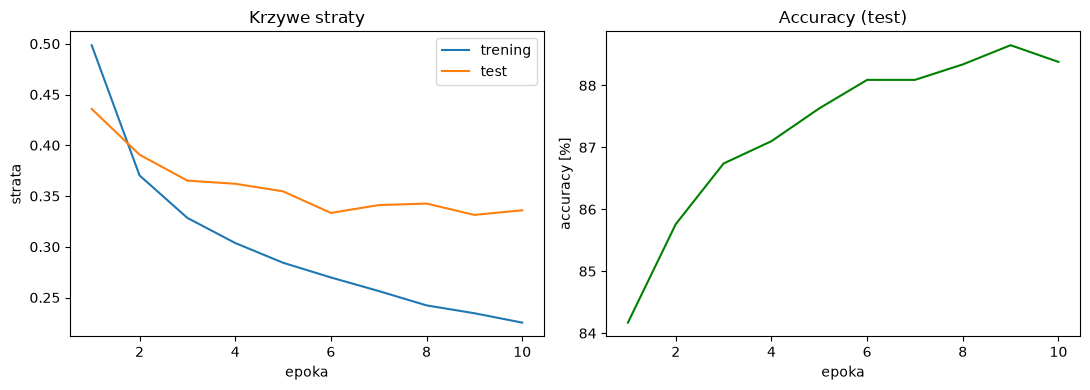

In [11]:
hist = wyniki[best_name]
model = best_model

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

epoki = range(1, len(hist["train_loss"]) + 1)

ax1.plot(epoki, hist["train_loss"], label="trening")
ax1.plot(epoki, hist["test_loss"], label="test")
ax1.set_xlabel("epoka"); ax1.set_ylabel("strata"); ax1.legend(); ax1.set_title("Krzywe straty")
ax2.plot(epoki, [a * 100 for a in hist["test_acc"]], color="green")
ax2.set_xlabel("epoka"); ax2.set_ylabel("accuracy [%]"); ax2.set_title("Accuracy (test)")
plt.tight_layout(); plt.show()

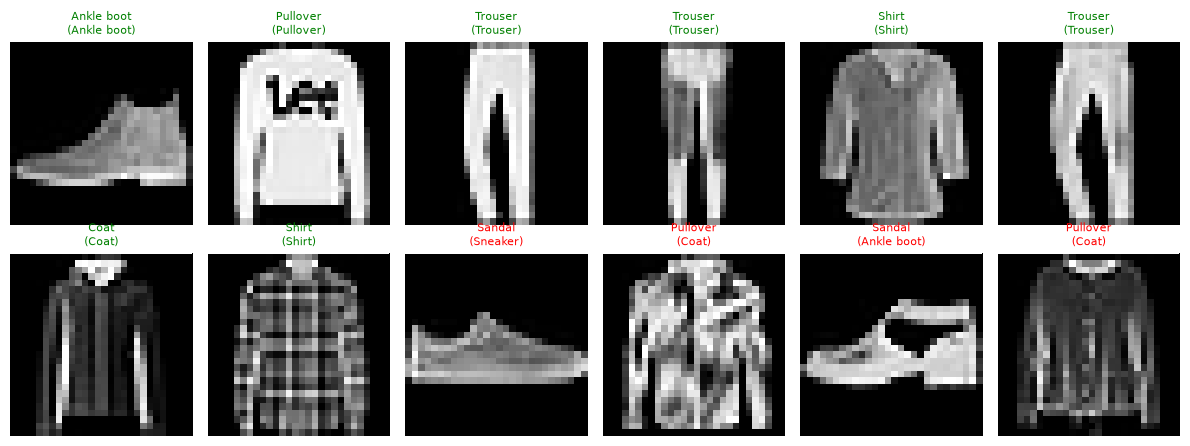

In [12]:
model.eval()
xb, yb = next(iter(test_dl))
with torch.no_grad():
    pred = model(xb.to(device)).argmax(1).cpu()

trafne = (pred == yb).nonzero(as_tuple=True)[0]
bledne = (pred != yb).nonzero(as_tuple=True)[0]

wybrane_indeksy = torch.cat((trafne[:8], bledne[:4]))

fig, axes = plt.subplots(2, 6, figsize=(12, 4.5))

for ax, i in zip(axes.flat, wybrane_indeksy):
    ax.imshow(xb[i].squeeze()*std + mean, cmap="gray")
    ok = pred[i].item() == yb[i].item()
    ax.set_title(f"{classes[pred[i]]}\n({classes[yb[i]]})", fontsize=8, color="green" if ok else "red")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [17]:
from sklearn.metrics import confusion_matrix
import numpy as np
all_pred, all_true = [], []
model.eval()
with torch.no_grad():
    for xb, yb in test_dl:
        all_pred.append(model(xb.to(device)).argmax(1).cpu())
        all_true.append(yb)
cm = confusion_matrix(torch.cat(all_true), torch.cat(all_pred))
np.fill_diagonal(cm_off := cm.copy(), 0)
i, j = np.unravel_index(cm_off.argmax(), cm_off.shape)
print(f"Najtrudniejsza para: {classes[i]} -> {classes[j]} ({cm_off[i,j]})")

Najtrudniejsza para: Pullover -> Coat (129)


Z analizy wyników zbioru FashionMNIST wynika, że model radzi sobie bardzo dobrze z odróżnianiem obiektów o różnym kształcie (np. spodnie i buty). Najczęstsze pomyłki występują w kategorii ubrań górnych, model myli np. T-shirt z koszulą, czy sweter z płaszczem. Wynika to z faktu, że obiekty te mają (w skali szarości przy niskiej rozdzielczości) bardzo zbliżony kształt, a sieć MLP traci część kluczowych informacji przestrzennych.